# 01 · Classical P300 test at Pz (no machine learning)

The baseline every model has to beat: the mean amplitude at Pz from 300 to 800 ms, compared between a person's probe and irrelevant epochs. No training is involved, so no folds are needed.

*Data: Gao et al. (2014), public Dryad release, doi:10.5061/dryad.2qc64. Own analysis; the plan (folds, training task, decision rule) was fixed before results.*

In [1]:
import os, json, numpy as np, matplotlib.pyplot as plt
# Point GAO_DIR at the "14 electrodes-30 subjects" folder of the Dryad release; GKT_WORK holds all derived files
os.environ.setdefault("GAO_DIR", "./data/14 electrodes-30 subjects/")
os.environ.setdefault("GKT_WORK", "./work/")
from gkt_utils import *
print("data:", GAO_DIR, "| work:", WORK)

data: ./data/14 electrodes-30 subjects/ | work: ./work/


In [2]:
X, G, PID, SES, STIM = load_dataset()
PIDS = sorted(set(PID.tolist()))
print(X.shape, "epochs x channels x samples |", len(PIDS), "people |",
      {k: int((STIM == v).sum()) for k, v in STIM_CODE.items()})

(23388, 12, 128) epochs x channels x samples | 30 people | {'irrelevant': 15583, 'probe': 3890, 'target': 3915}


## Score per epoch
One number per epoch: mean voltage at Pz (row 1) in 300–800 ms.

In [3]:
w = (TIME_MS >= 300) & (TIME_MS <= 800)
scores = X[:, PZ][:, w].mean(1)
np.save(P("scores_PzTest.npy"), scores)
print(scores[:5])

[ -0.8578291 -17.916374   -2.245421   -8.748171    1.30717  ]


## Person-level decision
For each person: within-person AUC (probability that a probe epoch scores higher than an irrelevant epoch) and a one-sided permutation test of mean(probe) − mean(irrelevant) with 2,000 shuffles; **knowledgeable if p < 0.05**. The same rule is used for every model.

In [4]:
summ, persons = evaluate(scores, PID, STIM)
show(summ, "Classical Pz test")
print("errors:", [r["code"] for r in persons if r["decision"] != r["group"]])
json.dump(dict(summary=summ, persons=persons), open(P("results_PzTest.json"), "w"), indent=1)

Classical Pz test        trial AUC 0.619 | person AUC 0.867 (perm p = 0.0002) | detected 12/15 | cleared 13/15 | BA 0.833
errors: ['H04', 'H08', 'L01', 'L05', 'L09']


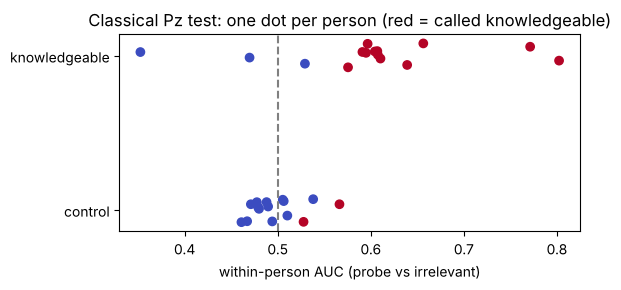

In [5]:
a = np.array([r["auc"] for r in persons]); y = np.array([r["group"] for r in persons])
plt.figure(figsize=(6, 3)); plt.scatter(a, y + np.random.default_rng(0).uniform(-.08, .08, len(y)), c=[r["decision"] for r in persons], cmap="coolwarm")
plt.yticks([0, 1], ["control", "knowledgeable"]); plt.axvline(0.5, ls="--", c="gray"); plt.xlabel("within-person AUC (probe vs irrelevant)")
plt.title("Classical Pz test: one dot per person (red = called knowledgeable)"); plt.tight_layout(); plt.show()

**Reading.** Trial AUC is low (single-trial Pz amplitude is noisy), yet the person-level test works well because it pools many trials per person. Expected: 12/15 detected, 13/15 cleared, balanced accuracy 0.83.